# Welcome to SMS Spam Detection!

In [1]:
import pandas as pd
from pathlib import Path

project_folder = Path.cwd()

if project_folder.name == "notebooks":
    project_folder = project_folder.parent

file_path = project_folder / "data" / "spam_messages_train.csv"

train_df = pd.read_csv(file_path)

In [2]:
train_df.head()

,label,text
0,ham,"Funny fact Nobody teaches volcanoes 2 erupt, t..."
1,ham,I sent my scores to sophas and i had to do sec...
2,spam,We know someone who you know that fancies you....
3,ham,Only if you promise your getting out as SOON a...
4,spam,Congratulations ur awarded either �500 of CD g...


In [3]:
shape = train_df.shape
print(f"total rows: {shape[0]}")
print(f"total columns: {shape[1]}")

total rows: 47392
total columns: 2


In [4]:
train_df.info() # column names, types, non-null counts, memory summary

<class 'pandas.DataFrame'>
RangeIndex: 47392 entries, 0 to 47391
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   label   47392 non-null  str  
 1   text    47392 non-null  str  
dtypes: str(2)
memory usage: 740.6 KB


In [5]:
train_df["label"].value_counts()

label
ham     28560
spam    18832
Name: count, dtype: int64

# Data quality Check

## checking the nulll values

In [6]:
train_df.isnull().sum()

label    0
text     0
dtype: int64

## checking the duplicates 

In [7]:
duplicates = train_df.duplicated().sum()
print(f"total duplicate datas {duplicates}")

total duplicate datas 2823


## checking the empty messages such as white spaces 

In [8]:
train_df["text"].str.strip().eq("").sum()

np.int64(0)

# Investigating duplicates and labels

In [9]:
duplicates = train_df[
    train_df.duplicated(keep=False)
]

duplicates.head(10)

,label,text
7,ham,No message..no responce..what happend?
50,spam,HMV BONUS SPECIAL 500 pounds of genuine HMV vo...
51,ham,He remains a bro amongst bros
61,spam,Buy Space Invaders 4 a chance 2 win orig Arcad...
66,ham,As per your request 'Maangalyam (Alaipayuthe)'...
73,ham,Honeybee Said: *I'm d Sweetest in d World* God...
75,spam,WINNER!! As a valued network customer you have...
79,ham,Sad story of a Man - Last week was my b'day. M...
94,ham,"Sorry, I'll call later"
102,ham,Wat r u doing?


In [10]:
label_counts = train_df.groupby("text")["label"].nunique()

conflicting_messages = label_counts[label_counts > 1]

print("Messages with conflicting labels:", len(conflicting_messages))

Messages with conflicting labels: 1


In [11]:
train_df["text"].value_counts().head(10)

text
click here to be removed                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           

# Train/ Validation/ test and overlaps

In [64]:
val_df = pd.read_csv(
    project_folder / "data" / "spam_messages_val.csv"
)

test_df = pd.read_csv(
    project_folder / "data" / "spam_messages_test.csv"
)

In [65]:
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

Training: (47392, 2)
Validation: (5923, 2)
Testing: (5926, 2)


## overlapping text between train and test

In [66]:
train_texts = set(train_df["text"])
test_texts = set(test_df["text"])

common_messages = train_texts.intersection(test_texts)

print("Messages shared between train and test:", len(common_messages))

Messages shared between train and test: 624


In [67]:
train_texts = set(train_df["text"])
val_texts = set(val_df["text"])
test_texts = set(test_df["text"])

print("Train vs Validation:",
      len(train_texts.intersection(val_texts)))

print("Train vs Test:",
      len(train_texts.intersection(test_texts)))

print("Validation vs Test:",
      len(val_texts.intersection(test_texts)))

Train vs Validation: 643
Train vs Test: 624
Validation vs Test: 99


In [68]:
# Create independent copies
train_clean = train_df.copy()
val_clean = val_df.copy()
test_clean = test_df.copy()

# Keep the test split as the reference
test_texts = set(test_clean["text"])

# Remove test messages from validation
val_clean = val_clean[
    ~val_clean["text"].isin(test_texts)
].copy()

# Remove validation and test messages from training
reserved_texts = set(val_clean["text"]) | test_texts

train_clean = train_clean[
    ~train_clean["text"].isin(reserved_texts)
].copy()

In [69]:
train_clean = train_clean.drop_duplicates().reset_index(drop=True)

val_clean = val_clean.drop_duplicates().reset_index(drop=True)

test_clean = test_clean.drop_duplicates().reset_index(drop=True)

In [70]:
print("Train:", train_clean.shape)
print("Validation:", val_clean.shape)
print("Test:", test_clean.shape)

print(
    "Train vs Validation:",
    len(set(train_clean["text"]) & set(val_clean["text"]))
)

print(
    "Train vs Test:",
    len(set(train_clean["text"]) & set(test_clean["text"]))
)

print(
    "Validation vs Test:",
    len(set(val_clean["text"]) & set(test_clean["text"]))
)

Train: (43321, 2)
Validation: (5755, 2)
Test: (5887, 2)
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0


In [71]:
conflicts = train_clean.groupby("text")["label"].nunique()

print("Conflicting texts:", (conflicts > 1).sum())

Conflicting texts: 1


In [72]:
conflicts = train_clean.groupby("text")["label"].nunique()
print(conflicts)

conflicting_texts = conflicts[conflicts > 1].index

train_clean[train_clean["text"].isin(conflicting_texts)]

text
 & who wants to help millions ?  8 is our theme for enron  , s 2000 houston united way campaign , which officially kicks off on august 9 , 2000 . last year , enron achieved a 17 percent increase overour 1998 campaign . this success would not have been possible without the support of all levels of management . enron  , s executive solicitation begins today , and we are counting on your leadership and strong support this year . your generous contribution will enable united way agencies in our community to continue providing quality programs and services . our goal this year is $ 2 , 310 , 000  ) a challenging goal , but we believe it is achievable with your help . including the dollar for dollar corporate match , enron  , s total pledge to united way in 2000 will be more than $ 4 . 5 million . to get there , we invite you to  & help millions  8 by making your pledge in one of the following way : ? alexis de tocqueville society ( gifts of $ 10 , 000 or more )  ) every member

,label,text
21865,spam,hi
37796,ham,hi


In [73]:
train_clean = train_clean[
    ~train_clean["text"].isin(conflicting_texts)
].reset_index(drop=True)

In [74]:
print("Training rows:", len(train_clean))

conflicts = train_clean.groupby("text")["label"].nunique()

print("Conflicting texts:", (conflicts > 1).sum())

Training rows: 43319
Conflicting texts: 0


In [75]:
train_clean["label"].value_counts()

label
ham     27319
spam    16000
Name: count, dtype: int64

In [76]:
train_clean["label"].value_counts(normalize=True) * 100

label
ham     63.064706
spam    36.935294
Name: proportion, dtype: float64

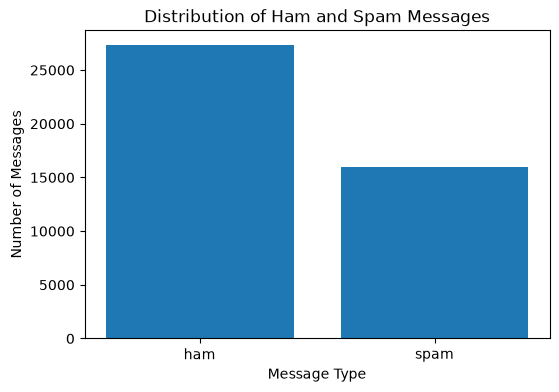

In [77]:
import matplotlib.pyplot as plt

label_counts = train_clean["label"].value_counts()

plt.figure(figsize=(6, 4))

plt.bar(label_counts.index, label_counts.values)

plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.title("Distribution of Ham and Spam Messages")

plt.show()

## Message Length Analysis

We calculate the number of characters in each message
to investigate whether spam and ham messages have
different length patterns.

In [78]:
train_clean["message_length"] = train_clean["text"].str.len()

train_clean[["label", "text", "message_length"]].head()

,label,text,message_length
0,ham,"Funny fact Nobody teaches volcanoes 2 erupt, t...",151
1,ham,I sent my scores to sophas and i had to do sec...,221
2,spam,We know someone who you know that fancies you....,101
3,ham,Only if you promise your getting out as SOON a...,124
4,spam,Congratulations ur awarded either �500 of CD g...,148


In [79]:
train_clean.groupby("label")["message_length"].mean()

label
ham     839.941616
spam    970.128687
Name: message_length, dtype: float64

In [80]:
train_clean.groupby("label")["message_length"].agg(
    ["min", "max", "mean", "median"]
)

,min,max,mean,median
label,,,,
ham,1,228353,839.941616,329.0
spam,2,28688,970.128687,442.0


## Message Length Distribution

We use a histogram to understand how message lengths are distributed
and identify whether unusually long messages affect the dataset.

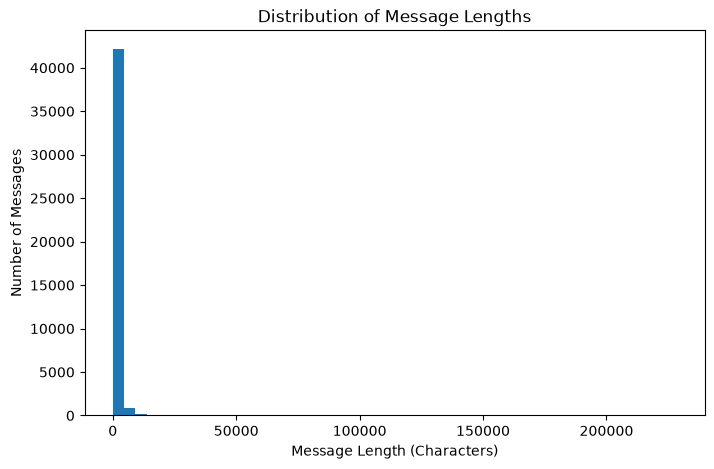

In [81]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(train_clean["message_length"], bins=50)

plt.xlabel("Message Length (Characters)")
plt.ylabel("Number of Messages")
plt.title("Distribution of Message Lengths")

plt.show()

In [82]:
train_clean["message_length"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
)

0.50     385.00
0.75     800.00
0.90    2007.20
0.95    3157.10
0.99    7670.28
Name: message_length, dtype: float64

In [83]:
limit = train_clean["message_length"].quantile(0.95)

print("95th percentile:", limit)

95th percentile: 3157.0999999999985


In [84]:
shorter_messages = train_clean[
    train_clean["message_length"] <= limit
]

print(shorter_messages)

      label                                               text  message_length
0       ham  Funny fact Nobody teaches volcanoes 2 erupt, t...             151
1       ham  I sent my scores to sophas and i had to do sec...             221
2      spam  We know someone who you know that fancies you....             101
3       ham  Only if you promise your getting out as SOON a...             124
4      spam  Congratulations ur awarded either �500 of CD g...             148
...     ...                                                ...             ...
43313   ham  group , due to the recent drop in day - ahead ...            1494
43314   ham  start date : 1 / 7 / 02 ; hourahead hour : 13 ...             231
43315   ham  please change the sitara tickets dating back t...            2650
43317   ham  just to get things stirred up : the estate wil...             389
43318   ham  sorry for the oversight . bill - - - - - origi...            2426

[41153 rows x 3 columns]


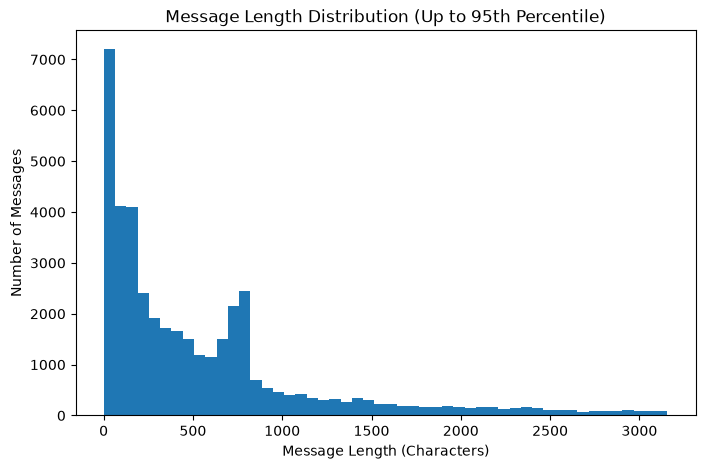

In [85]:
plt.figure(figsize=(8, 5))

plt.hist(shorter_messages["message_length"], bins=50)

plt.xlabel("Message Length (Characters)")
plt.ylabel("Number of Messages")
plt.title("Message Length Distribution (Up to 95th Percentile)")

plt.show()

In [86]:
ham_lengths = shorter_messages[
    shorter_messages["label"] == "ham"
]["message_length"]

spam_lengths = shorter_messages[
    shorter_messages["label"] == "spam"
]["message_length"]

print(ham_lengths)
print(spam_lengths)

0         151
1         221
3         124
5          42
6          41
         ... 
43313    1494
43314     231
43315    2650
43317     389
43318    2426
Name: message_length, Length: 26193, dtype: int64
2        101
4        148
10       129
16       119
23       160
        ... 
43302    303
43304    152
43306    279
43311    842
43312     39
Name: message_length, Length: 14960, dtype: int64


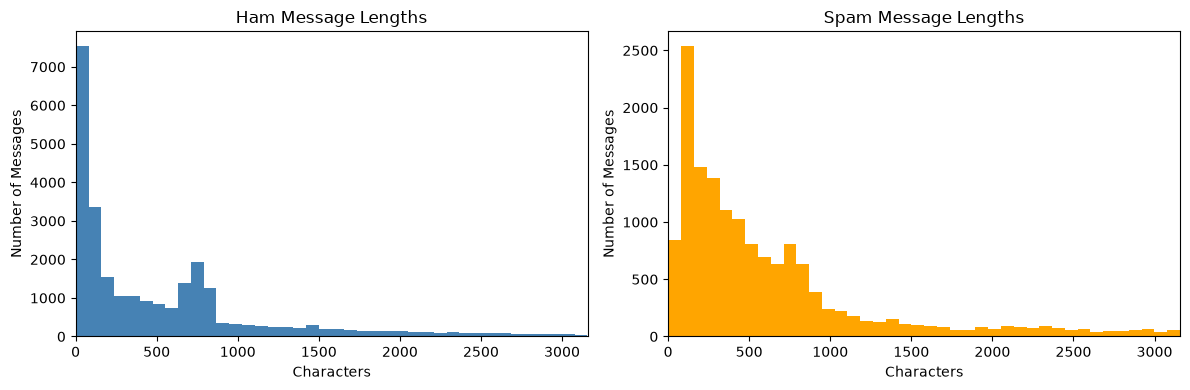

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(ham_lengths, bins=40, color="steelblue")
axes[0].set_title("Ham Message Lengths")
axes[0].set_xlabel("Characters")
axes[0].set_ylabel("Number of Messages")
axes[0].set_xlim(0, limit)

axes[1].hist(spam_lengths, bins=40, color="orange")
axes[1].set_title("Spam Message Lengths")
axes[1].set_xlabel("Characters")
axes[1].set_ylabel("Number of Messages")
axes[1].set_xlim(0, limit)

plt.tight_layout()
plt.show()

## Box Plot and Outlier Analysis

In [88]:
Q1 = train_clean["message_length"].quantile(0.25)
Q3 = train_clean["message_length"].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 120.0
Q3: 800.0
IQR: 680.0


In [89]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Lower bound: -900.0
Upper bound: 1820.0


In [90]:
outliers = train_clean[
    (train_clean["message_length"] < lower_bound) |
    (train_clean["message_length"] > upper_bound)
]

print("Potential outliers:", len(outliers))
print("Percentage:", len(outliers) / len(train_clean) * 100)

Potential outliers: 4850
Percentage: 11.19601098824996


In [91]:
train_clean.groupby("label")["message_length"].mean()

label
ham     839.941616
spam    970.128687
Name: message_length, dtype: float64

## Message Length Variability Analysis

In [92]:
train_clean.groupby("label")["message_length"].std()

label
ham     3482.019841
spam    1656.695389
Name: message_length, dtype: float64

In [93]:
train_clean.groupby("label")["message_length"].agg(
    ["count", "mean", "median", "var", "std"]
)

,count,mean,median,var,std
label,,,,,
ham,27319,839.941616,329.0,1.212446e+07,3482.019841
spam,16000,970.128687,442.0,2.744640e+06,1656.695389


## Box Plot Analysis of Ham and Spam Message Lengths

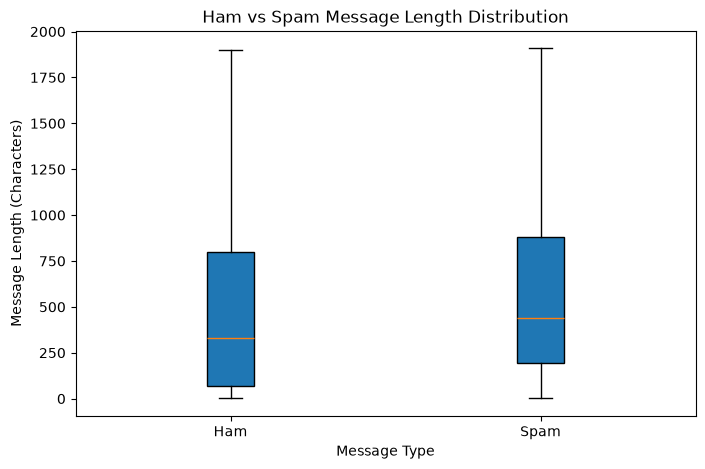

In [94]:
import matplotlib.pyplot as plt

ham_lengths = train_clean[
    train_clean["label"] == "ham"
]["message_length"]

spam_lengths = train_clean[
    train_clean["label"] == "spam"
]["message_length"]

plt.figure(figsize=(8, 5))

plt.boxplot(
    [ham_lengths, spam_lengths],
    tick_labels=["Ham", "Spam"],
    showfliers=False,
    patch_artist=True
)

plt.xlabel("Message Type")
plt.ylabel("Message Length (Characters)")
plt.title("Ham vs Spam Message Length Distribution")

plt.show()

## NLP — Exploring Raw Message Text

In [95]:
print('sample ham message:\n')
ham_samples = train_clean[train_clean["label"] == 'ham']['text'].head(3)

for message in ham_samples:
    print(repr(message[:200]))
    print('-------------------')

sample ham message:

'Funny fact Nobody teaches volcanoes 2 erupt, tsunamis 2 arise, hurricanes 2 sway aroundn no 1 teaches hw 2 choose a wife Natural disasters just happens'
-------------------
'I sent my scores to sophas and i had to do secondary application for a few schools. I think if you are thinking of applying, do a research on cost also. Contact joke ogunrinde, her school is one me th'
-------------------
"Only if you promise your getting out as SOON as you can. And you'll text me in the morning to let me know you made it in ok."
-------------------


In [96]:
print("Sample spam messages:\n")

spam_samples = train_clean[
    train_clean["label"] == "spam"
]["text"].head(3)

for message in spam_samples:
    print(repr(message[:200]))
    print("--------------------")

Sample spam messages:

'We know someone who you know that fancies you. Call 09058097218 to find out who. POBox 6, LS15HB 150p'
--------------------
'Congratulations ur awarded either �500 of CD gift vouchers & Free entry 2 our �100 weekly draw txt MUSIC to 87066 TnCs www.Ldew.com1win150ppmx3age16'
--------------------
'Free tones Hope you enjoyed your new content. text stop to 61610 to unsubscribe. help:08712400602450p Provided by tones2you.co.uk'
--------------------


In [97]:
message = spam_samples.iloc[1]

print("Original message:")
print(message)

print("\nTokens:")
tokens = message.split()

print(tokens)

Original message:
Congratulations ur awarded either �500 of CD gift vouchers & Free entry 2 our �100 weekly draw txt MUSIC to 87066 TnCs www.Ldew.com1win150ppmx3age16

Tokens:
['Congratulations', 'ur', 'awarded', 'either', '�500', 'of', 'CD', 'gift', 'vouchers', '&', 'Free', 'entry', '2', 'our', '�100', 'weekly', 'draw', 'txt', 'MUSIC', 'to', '87066', 'TnCs', 'www.Ldew.com1win150ppmx3age16']


In [98]:
lowercase_tokens = message.lower().split()

print(lowercase_tokens)

['congratulations', 'ur', 'awarded', 'either', '�500', 'of', 'cd', 'gift', 'vouchers', '&', 'free', 'entry', '2', 'our', '�100', 'weekly', 'draw', 'txt', 'music', 'to', '87066', 'tncs', 'www.ldew.com1win150ppmx3age16']


In [99]:
import string

print(string.punctuation)

!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~


In [100]:
message = "FREE prize!!! Claim $500 now."

cleaned = message.lower().translate(
    str.maketrans("", "", string.punctuation)
)

print("Original:", message)
print("Cleaned:", cleaned)

Original: FREE prize!!! Claim $500 now.
Cleaned: free prize claim 500 now


## Stopword Removal Experiment

Explore how removing common words changes a message.
This is only an experiment; the original dataset remains unchanged.

In [101]:
message = "You are the winner of a free prize"

stopwords = {"you", "are", "the", "of", "a"}

tokens = message.lower().split()

filtered_tokens = [
    word for word in tokens
    if word not in stopwords
]

print("Original tokens:", tokens)
print("Filtered tokens:", filtered_tokens)

Original tokens: ['you', 'are', 'the', 'winner', 'of', 'a', 'free', 'prize']
Filtered tokens: ['winner', 'free', 'prize']


## Feature Extraction  Bag of Words

We use CountVectorizer to transform text messages into numerical
word-frequency vectors.

In [102]:
from sklearn.feature_extraction.text import CountVectorizer

In [103]:
messages = [
    "win free prize",
    "free money now",
    "call me now"
]

In [104]:
vectorizer = CountVectorizer() #learning means discovering the vocabulary and assigning feature positions.

X = vectorizer.fit_transform(messages)
print(vectorizer.get_feature_names_out())

['call' 'free' 'me' 'money' 'now' 'prize' 'win']


In [105]:
print('matrix')
print(X.toarray())

matrix
[[0 1 0 0 0 1 1]
 [0 1 0 1 1 0 0]
 [1 0 1 0 1 0 0]]


In [106]:
new_message = ["free free free prize"]

new_vector = vectorizer.transform(new_message)

print(new_vector.toarray())

unknown_message = ["free lottery prize"]

unknown_vector = vectorizer.transform(unknown_message)

print(unknown_vector.toarray()) 

[[0 3 0 0 0 1 0]]
[[0 1 0 0 0 1 0]]


In [107]:
print("Matrix type:", type(X))
print("Matrix shape:", X.shape)
print("Nonzero entries:", X.nnz)

Matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Matrix shape: (3, 7)
Nonzero entries: 9


In [108]:
bow_df = pd.DataFrame(
    X.toarray(),
    columns=vectorizer.get_feature_names_out()
)

bow_df

,call,free,me,money,now,prize,win
0,0,1,0,0,0,1,1
1,0,1,0,1,1,0,0
2,1,0,1,0,1,0,0


## Bag of Words — Real Training Dataset

In [109]:
real_vectorizer = CountVectorizer()

X_train_bow = real_vectorizer.fit_transform(
    train_clean["text"]
)

In [110]:
print("Training matrix shape:", X_train_bow.shape)

print("Vocabulary size:", len(
    real_vectorizer.get_feature_names_out()
))

print("Nonzero entries:", X_train_bow.nnz)

Training matrix shape: (43319, 160013)
Vocabulary size: 160013
Nonzero entries: 3345508


## Bag of Words — Vocabulary Filtering Experiment

Investigate how minimum document frequency affects
vocabulary size and matrix sparsity.

In [111]:
filtered_vectorizer = CountVectorizer(min_df=5)

X_train_filtered = filtered_vectorizer.fit_transform(
    train_clean["text"]
)

In [112]:
print("Original shape:", X_train_bow.shape)
print("Filtered shape:", X_train_filtered.shape)

print("Original vocabulary:", len(real_vectorizer.get_feature_names_out()))
print("Filtered vocabulary:", len(filtered_vectorizer.get_feature_names_out()))

Original shape: (43319, 160013)
Filtered shape: (43319, 38765)
Original vocabulary: 160013
Filtered vocabulary: 38765


## Bag of Words — Minimum and Maximum Document Frequency

Investigating the effect of min_df and max_df on vocabulary size.

In [113]:
frequency_vectorizer = CountVectorizer(
    min_df=5,
    max_df=0.90
)

X_train_frequency = frequency_vectorizer.fit_transform(
    train_clean["text"]
)

In [114]:
print("Original vocabulary:", X_train_bow.shape[1])
print("min_df=5 vocabulary:", X_train_filtered.shape[1])
print("Combined vocabulary:", X_train_frequency.shape[1])

Original vocabulary: 160013
min_df=5 vocabulary: 38765
Combined vocabulary: 38765
